# Compare models

Reads every run folder under `models/` and plots them side by side. A run folder is any folder with a
`metrics.json` (folders named `seed_*` are the seeds of their parent run). Train runs with a name so they
don't overwrite each other:

```
python -m engines.neural_network.train --name more_dropout      # -> models/neural_network/more_dropout/
```

**Adding a baseline** (median, linear, LightGBM, ...): split with `engines.common.load_splits(...)` using the
same seeds as the config, score with `engines.common.regression_metrics`, and write the same files:

| file | content | needed for |
|---|---|---|
| `seed_<s>/metrics.json` | `{split: {"overall": {...}, "<type>": {..., "n": n}}}` | everything |
| `seed_<s>/test_predictions.csv` | `property_type, district, actual, predicted` | error plots |
| `seed_<s>/history.csv` | `epoch, train_loss, val_loss` | learning curves (optional) |

Compare **test** numbers only, and only between runs that used the same seeds.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import NullFormatter

LAB = Path.cwd() if (Path.cwd() / "engines").exists() else Path.cwd().parent
MODELS_DIR = Path(os.environ.get("MODELS_DIR", LAB / "models"))

FOCUS_RUN = None  # run shown in the detail plots; None = best test MdAPE among runs with the most seeds
REF_RUN = None    # run the others are compared against; same default
MIN_ROWS = 10     # property types with fewer test rows are left out of the detail plots
METRICS = ["median_ape", "rmse_log", "r2", "mape", "mae", "rmse"]
LOWER_BETTER = {"median_ape": True, "rmse_log": True, "r2": False, "mape": True, "mae": True, "rmse": True}
LABEL = {"median_ape": "MdAPE %", "rmse_log": "RMSE log", "r2": "R²", "mape": "MAPE %", "mae": "MAE $", "rmse": "RMSE $"}

# palette (light mode): categorical slots in fixed order, sequential blue ramp, chart chrome
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110,
})
print("models dir:", MODELS_DIR)

models dir: C:\Projects\CADT\property-valuation-model\laboratory\models


## Load runs

In [2]:
def seed_dirs(run_dir):
    """[(seed, folder)] for a run: its seed_* folders, else the run folder itself (seed unknown)."""
    seeds = sorted((int(p.name[5:]), p) for p in run_dir.glob("seed_*") if (p / "metrics.json").exists())
    return seeds or [(None, run_dir)]

runs = {}
for f in sorted(MODELS_DIR.rglob("metrics.json")):
    d = f.parent
    if not d.name.startswith("seed_"):
        runs[d.relative_to(MODELS_DIR).as_posix()] = d

rows = []
for run, d in runs.items():
    for seed, sd in seed_dirs(d):
        for split, groups in json.load(open(sd / "metrics.json")).items():
            for group, m in groups.items():
                rows += [{"run": run, "seed": seed, "split": split, "group": group, "metric": k,
                          "value": m[k], "n": m.get("n")} for k in METRICS if k in m]
scores = pd.DataFrame(rows)
if scores.empty:
    raise SystemExit(f"no runs under {MODELS_DIR} - train one first")
test = scores[scores.split == "test"]
overall = test[test.group == "overall"]

order = (overall[overall.metric == "median_ape"].groupby("run").value.mean().sort_values().index.tolist())
n_seeds = overall[overall.metric == "r2"].groupby("run").size()

# Which data a run was scored on: test rows per seed (sum over property types). Runs trained on a different
# CSV (e.g. data.csv vs data_filtered.csv) have different test sets, so their scores are not comparable.
rows_per_seed = (test[(test.group != "overall") & (test.metric == "median_ape")]
                 .groupby(["run", "seed"], dropna=False).n.sum())
signature = rows_per_seed.groupby(level="run").apply(lambda s: tuple(s.droplevel("run").sort_index().items()))
main_sig = signature.value_counts().index[0]  # the dataset most runs were scored on

candidates = [r for r in order if signature[r] == main_sig]
best = next(r for r in candidates if n_seeds[r] == n_seeds[candidates].max())  # 1-seed runs are too noisy
FOCUS = FOCUS_RUN or best
REF = REF_RUN or best
comparable = [r for r in order if signature[r] == signature[REF]]  # same test rows as the reference
other_data = [r for r in order if r not in comparable]
print(f"{len(runs)} runs; focus = {FOCUS}; reference = {REF}")
if other_data:
    print(f"scored on different test rows than {REF} (other data file?), left out of the comparisons below: "
          + ", ".join(other_data))

10 runs; focus = gradient_boosting/ensemble; reference = gradient_boosting/ensemble
scored on different test rows than gradient_boosting/ensemble (other data file?), left out of the comparisons below: neural_network/base


## Test scores (mean ± std over seeds)
Sorted by test MdAPE. `seeds` = how many splits each number averages. `test rows` = mean test rows per seed;
runs with a different count were trained on a different data file and are **not comparable** (marked ✗).

In [3]:
def pm(v):
    m, s = v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)
    return f"{m:,.0f} ± {s:,.0f}" if abs(m) >= 1000 else f"{m:.3f} ± {s:.3f}"

table = overall.pivot_table(index="run", columns="metric", values="value", aggfunc=pm)[METRICS]
table.columns = [LABEL[c] for c in table.columns]
table.insert(0, "seeds", n_seeds)
table.insert(1, "test rows", rows_per_seed.groupby(level="run").mean().round().astype(int))
table.insert(2, f"same data as {REF}", ["✓" if r in comparable else "✗" for r in table.index])
table.loc[order]

,seeds,test rows,same data as gradient_boosting/ensemble,MdAPE %,RMSE log,R²,MAPE %,MAE $,RMSE $
run,,,,,,,,,
gradient_boosting/ensemble,5,2060,✓,21.143 ± 0.630,0.415 ± 0.007,0.783 ± 0.031,31.870 ± 1.386,"106,223 ± 3,258","285,559 ± 18,335"
neural_network/filtered,5,2060,✓,22.962 ± 0.637,0.426 ± 0.007,0.765 ± 0.018,33.977 ± 1.798,"111,721 ± 2,495","297,935 ± 15,554"
neural_network/base,5,2496,✗,23.030 ± 0.614,0.455 ± 0.014,0.683 ± 0.091,36.420 ± 2.134,"121,471 ± 12,296","393,187 ± 109,950"
ridge_regression/interact,5,2060,✓,26.063 ± 0.367,0.465 ± 0.007,0.725 ± 0.027,37.630 ± 0.827,"123,993 ± 2,974","322,235 ± 14,815"
linear_regression/interact,5,2060,✓,26.069 ± 0.607,0.466 ± 0.008,0.727 ± 0.027,37.649 ± 1.005,"123,299 ± 3,129","320,968 ± 15,344"
linear_regression/base,5,2060,✓,26.615 ± 0.293,0.476 ± 0.006,0.694 ± 0.028,38.898 ± 1.001,"129,714 ± 3,020","339,780 ± 11,806"
ridge_regression/base,5,2060,✓,26.727 ± 0.515,0.475 ± 0.005,0.694 ± 0.027,38.733 ± 0.972,"129,922 ± 2,545","339,870 ± 10,140"
median_baseline/min_group_1,5,2060,✓,28.049 ± 0.731,0.520 ± 0.016,0.675 ± 0.081,44.929 ± 2.016,"135,122 ± 4,715","347,501 ± 39,994"
median_baseline/base,5,2060,✓,28.231 ± 0.680,0.528 ± 0.016,0.665 ± 0.085,46.956 ± 2.075,"137,155 ± 5,282","352,683 ± 41,095"


## Overall test metrics per run
Each dot is one seed (one split); the black tick and line are the mean ± 1 std. Runs whose ranges overlap
heavily are not really different.

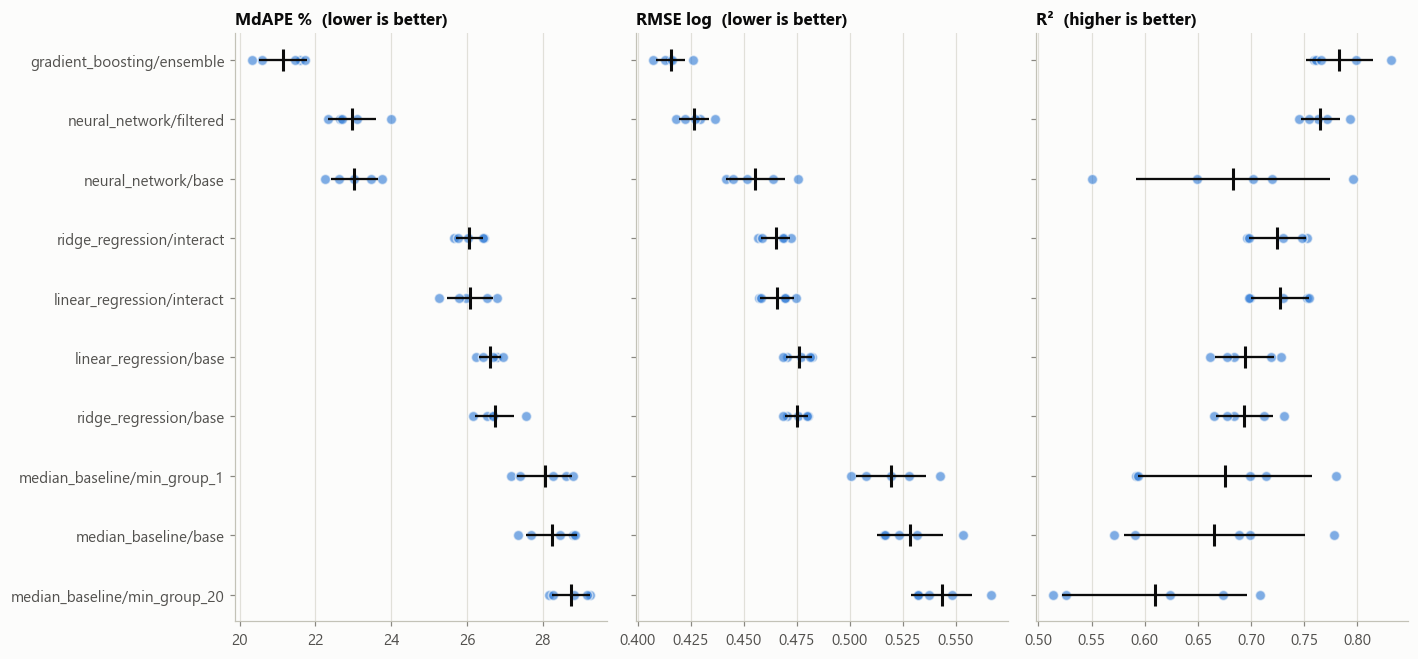

In [4]:
show = ["median_ape", "rmse_log", "r2"]
fig, axes = plt.subplots(1, 3, figsize=(13, 0.45 * len(order) + 1.6), sharey=True)
for ax, m in zip(axes, show):
    for i, run in enumerate(order):
        v = overall[(overall.run == run) & (overall.metric == m)].value
        ax.scatter(v, np.full(len(v), i), s=44, color=SERIES[0], alpha=0.6, edgecolor=SURFACE, linewidth=1, zorder=3)
        sd = v.std(ddof=1) if len(v) > 1 else 0
        ax.errorbar(v.mean(), i, xerr=sd, fmt="|", markersize=14, markeredgewidth=2, color=INK,
                    elinewidth=1.5, capsize=0, zorder=4)
    ax.set_title(f"{LABEL[m]}  ({'lower' if LOWER_BETTER[m] else 'higher'} is better)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), order)
axes[0].invert_yaxis()
fig.tight_layout()

## Is the difference real? (paired over the same seeds)
Each run minus the reference run, seed by seed, so split luck cancels out. If the error bar (std of the
per-seed differences) crosses zero, the difference is within noise. Only runs scored on the same test rows as the
reference are compared.

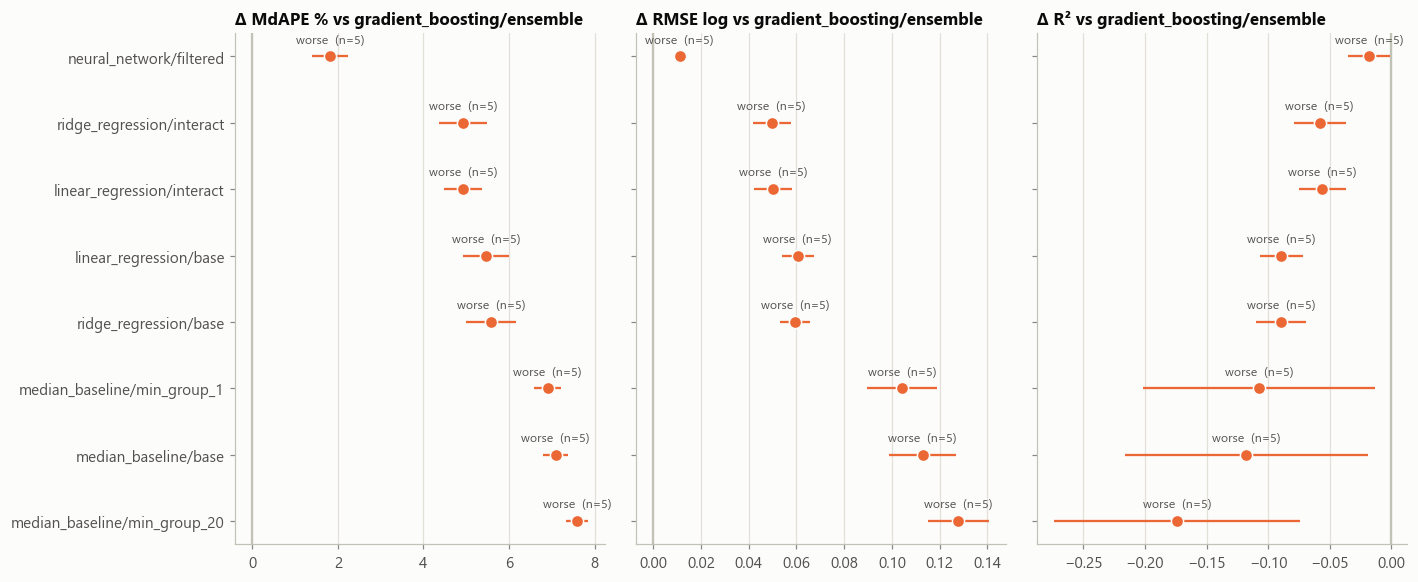

In [5]:
def paired(metric):
    ref = overall[(overall.run == REF) & (overall.metric == metric)].set_index("seed").value
    out = []
    for run in comparable:
        if run == REF:
            continue
        v = overall[(overall.run == run) & (overall.metric == metric)].set_index("seed").value
        common = ref.index.intersection(v.index).dropna()
        if len(common):
            d = v[common] - ref[common]
            out.append((run, d.mean(), d.std(ddof=1) if len(d) > 1 else 0.0, len(d)))
    return out

fig, axes = plt.subplots(1, 3, figsize=(13, 0.45 * max(len(comparable) - 1, 1) + 1.8), sharey=True)
for ax, m in zip(axes, show):
    res = paired(m)
    for i, (run, mu, sd, n) in enumerate(res):
        better = (mu < 0) == LOWER_BETTER[m]
        real = abs(mu) > sd and n > 1
        ax.errorbar(mu, i, xerr=sd, fmt="o", markersize=8, color=SERIES[0] if better else SERIES[1],
                    markeredgecolor=SURFACE, elinewidth=1.5, capsize=0, zorder=3)
        ax.annotate(("better" if better else "worse") + ("" if real else " · noise") + f"  (n={n})",
                    (mu, i), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax.axvline(0, color=AXIS, linewidth=1.5, zorder=2)
    ax.set_title(f"Δ {LABEL[m]} vs {REF}")
    ax.grid(axis="y", visible=False)
    if res:
        ax.set_yticks(range(len(res)), [r[0] for r in res])
axes[0].invert_yaxis()
if not paired(show[0]):
    print(f"no other run shares seeds with {REF} - nothing to compare")
fig.tight_layout()

## Error by property type
Mean test MdAPE per run and property type (runs on the reference's test rows). Darker = bigger error.

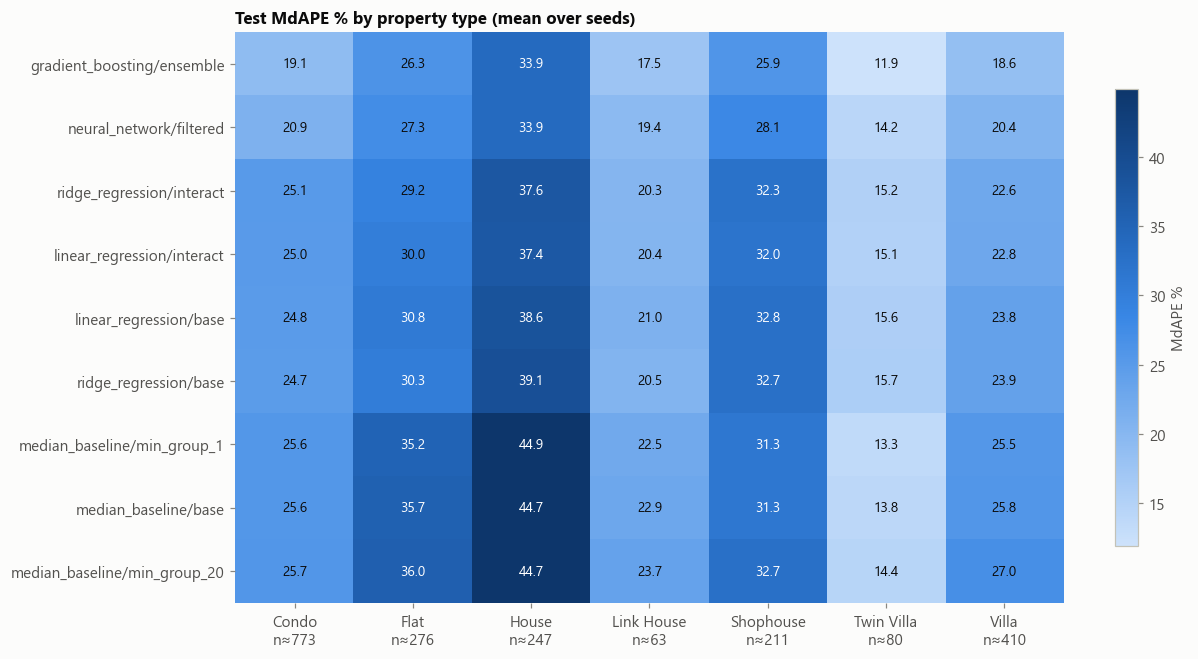

In [6]:
by_type = test[(test.group != "overall") & (test.metric == "median_ape") & test.run.isin(comparable)]
heat = by_type.pivot_table(index="run", columns="group", values="value", aggfunc="mean").loc[comparable]
n_test = by_type.groupby("group").n.mean().round().astype(int)
cmap = LinearSegmentedColormap.from_list("blues", BLUES)
fig, ax = plt.subplots(figsize=(1.25 * heat.shape[1] + 3, 0.5 * len(comparable) + 1.6))
im = ax.imshow(heat.values, cmap=cmap, aspect="auto")
for (i, j), v in np.ndenumerate(heat.values):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if im.norm(v) > 0.55 else INK)
ax.set_xticks(range(heat.shape[1]), [f"{c}\nn≈{n_test[c]}" for c in heat.columns])
ax.set_yticks(range(len(comparable)), comparable)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Test MdAPE % by property type (mean over seeds)")
fig.colorbar(im, ax=ax, shrink=0.8, label="MdAPE %")
fig.tight_layout()

## Learning curves (focus run)
Train vs validation loss per seed. The dashed line is the epoch whose weights were kept.

In [7]:
hist = [(s, sd / "history.csv") for s, sd in seed_dirs(runs[FOCUS]) if (sd / "history.csv").exists()]
if not hist:
    print(f"{FOCUS}: no history.csv")
else:
    cols = min(len(hist), 3)
    rows_ = int(np.ceil(len(hist) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(4.4 * cols, 3.1 * rows_), squeeze=False, sharey=True)
    for ax, (seed, f) in zip(axes.flat, hist):
        h = pd.read_csv(f)
        ax.plot(h.epoch, h.train_loss, color=SERIES[0], label="train")
        ax.plot(h.epoch, h.val_loss, color=SERIES[1], label="validation")
        kept = h.loc[h.val_loss.idxmin()]
        ax.axvline(kept.epoch, color=MUTED, linestyle="--", linewidth=1)
        ax.annotate(f"best epoch {int(kept.epoch)}", (kept.epoch, 0.04), xycoords=("data", "axes fraction"),
                    xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2)
        ax.set_title(f"seed {seed}" if seed is not None else FOCUS)
        ax.set_xlabel("epoch")
    for ax in axes.flat[len(hist):]:
        ax.set_visible(False)
    axes[0, 0].set_ylabel("loss (log price)")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncol=2)
    fig.suptitle(f"Learning curves: {FOCUS}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()

gradient_boosting/ensemble: no history.csv


## Predicted vs actual (focus run, all seeds' test rows)
Log scales. Diagonal = perfect; the band is ±25 %. Points above the line are over-predicted. Types with fewer than `MIN_ROWS` test rows per seed are skipped
(`n` in the titles is pooled over all seeds).

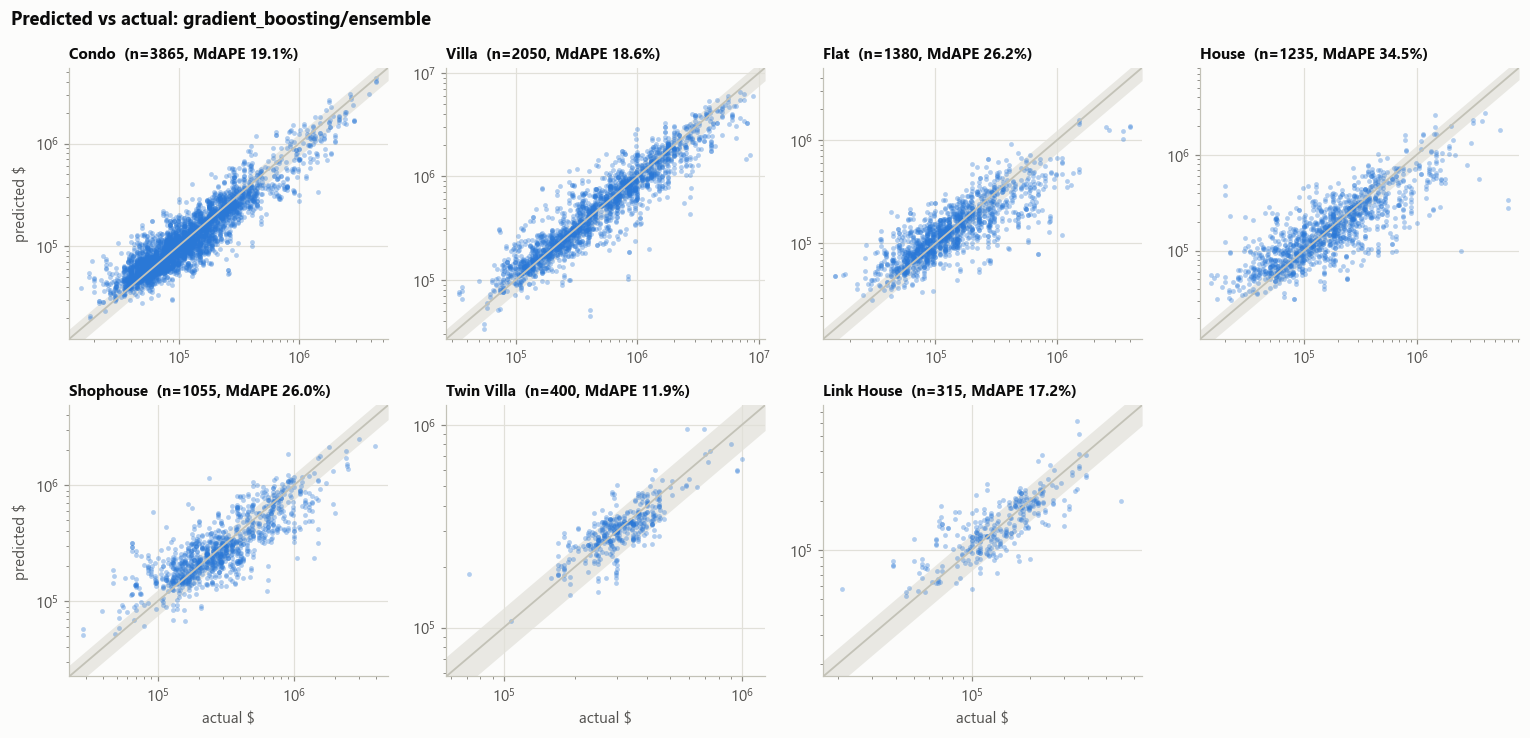

In [8]:
def load_preds(run):
    parts = []
    for seed, sd in seed_dirs(runs[run]):
        if (sd / "test_predictions.csv").exists():
            parts.append(pd.read_csv(sd / "test_predictions.csv").assign(seed=seed, run=run))
    return pd.concat(parts, ignore_index=True) if parts else None

preds = {run: p for run in order if (p := load_preds(run)) is not None}
for p in preds.values():
    p["ape"] = (p.predicted - p.actual).abs() / p.actual * 100
    p["log_err"] = np.log(p.predicted / p.actual)

p = preds.get(FOCUS)
if p is None:
    print(f"{FOCUS}: no test_predictions.csv")
else:
    counts = p.property_type.value_counts() / p.seed.nunique()  # test rows per seed
    types = counts[counts >= MIN_ROWS].index.tolist()
    cols = 4
    fig, axes = plt.subplots(int(np.ceil(len(types) / cols)), cols, figsize=(14, 3.4 * np.ceil(len(types) / cols)),
                             squeeze=False)
    for ax, t in zip(axes.flat, types):
        q = p[p.property_type == t]
        lo, hi = q[["actual", "predicted"]].min().min() * 0.8, q[["actual", "predicted"]].max().max() * 1.25
        line = np.array([lo, hi])
        ax.fill_between(line, line * 0.75, line * 1.25, color=GRID, alpha=0.7, linewidth=0)
        ax.plot(line, line, color=AXIS, linewidth=1.2)
        ax.scatter(q.actual, q.predicted, s=10, color=SERIES[0], alpha=0.35, linewidth=0)
        ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_title(f"{t}  (n={len(q)}, MdAPE {q.ape.median():.1f}%)", fontsize=10)
    for ax in axes.flat[len(types):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("predicted $")
    for ax in axes[-1]:
        ax.set_xlabel("actual $")
    fig.suptitle(f"Predicted vs actual: {FOCUS}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()

## Error vs price level (all runs)
Test MdAPE within price deciles (deciles of the actual price). Shows whether a model is worse on cheap or on
expensive listings. Only runs on the reference's test rows, at most the first 8 in the ranking.

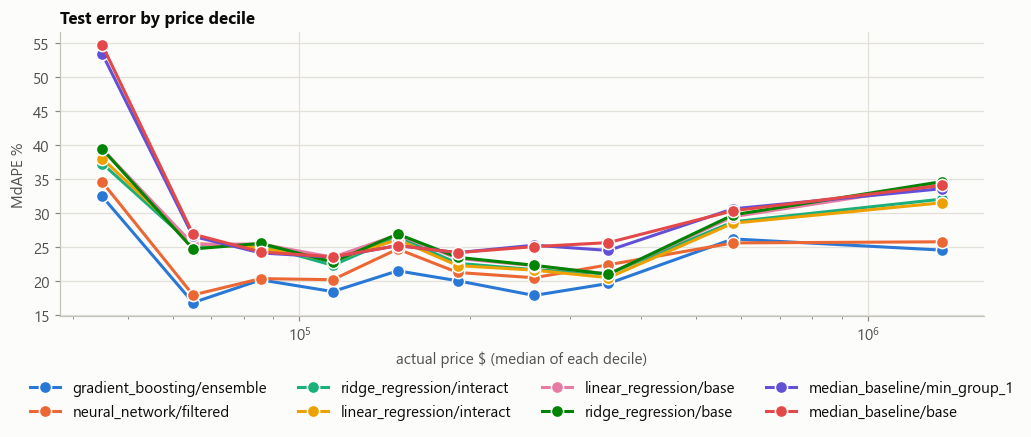

In [9]:
if preds:
    fig, ax = plt.subplots(figsize=(10, 4.2))
    shown = [r for r in comparable if r in preds][:8]
    for k, run in enumerate(shown):
        q = preds[run]
        dec = pd.qcut(q.actual, 10, duplicates="drop")
        g = q.groupby(dec, observed=True).agg(price=("actual", "median"), ape=("ape", "median"))
        ax.plot(g.price, g.ape, color=SERIES[k], marker="o", markersize=8, markeredgecolor=SURFACE, label=run)
    ax.set_xscale("log")
    ax.set_xlabel("actual price $ (median of each decile)")
    ax.set_ylabel("MdAPE %")
    ax.set_title("Test error by price decile")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=min(len(shown), 4))
    fig.tight_layout()

## Bias by property type (focus run)
log(predicted / actual) per test row. The box should sit on 0; above 0 = the model over-prices that type,
below = under-prices. Width of the box = how spread out the errors are.

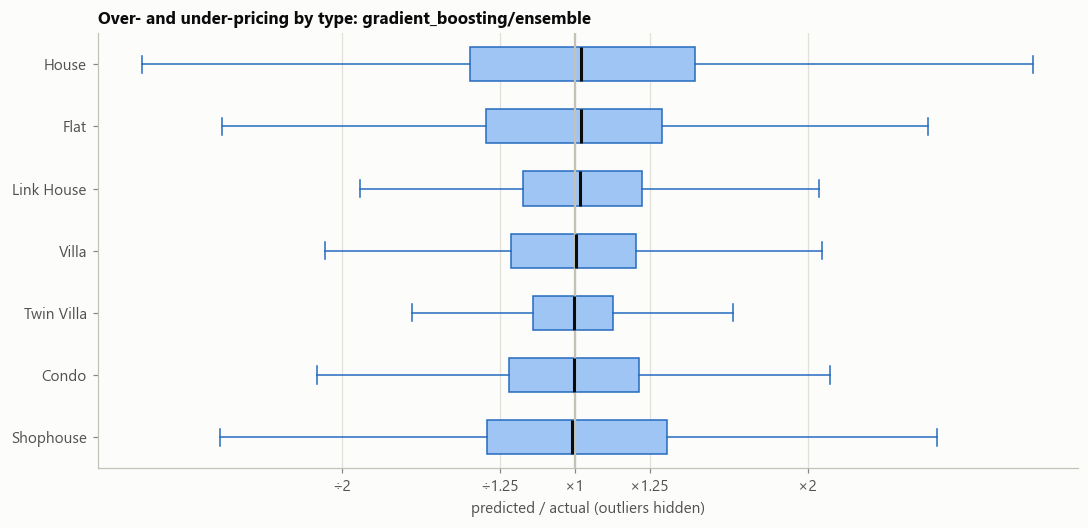

In [10]:
if p is not None:
    counts = p.property_type.value_counts() / p.seed.nunique()  # test rows per seed
    types = p[p.property_type.isin(counts[counts >= MIN_ROWS].index)].groupby("property_type").log_err.median().sort_values().index.tolist()
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(types) + 1.4))
    ax.boxplot([p[p.property_type == t].log_err for t in types], orientation="horizontal", widths=0.55, patch_artist=True,
               showfliers=False, medianprops={"color": INK, "linewidth": 2},
               boxprops={"facecolor": BLUES[1], "edgecolor": BLUES[4]},
               whiskerprops={"color": BLUES[4]}, capprops={"color": BLUES[4]})
    ax.set_yticks(range(1, len(types) + 1), types)
    ax.axvline(0, color=AXIS, linewidth=1.5)
    ticks = np.log([0.5, 0.8, 1, 1.25, 2])
    ax.set_xticks(ticks, ["÷2", "÷1.25", "×1", "×1.25", "×2"])
    ax.set_xlabel("predicted / actual (outliers hidden)")
    ax.set_title(f"Over- and under-pricing by type: {FOCUS}")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()

## Worst districts (focus run)
Districts with at least 30 test rows (pooled over all seeds), ranked by MdAPE. Where to look for data problems or missing features.

In [11]:
if p is not None:
    d = (p.groupby("district").agg(rows_all_seeds=("ape", "size"), mdape=("ape", "median"),
                                    bias=("log_err", "median"))
         .query("rows_all_seeds >= 30").sort_values("mdape", ascending=False))
    d["bias"] = np.exp(d["bias"]).map(lambda x: f"×{x:.2f}")
    display(d.head(15).round(1))

,rows_all_seeds,mdape,bias
district,,,
Ta Khmau,52,36.3,×1.00
7 Makara,232,33.2,×0.89
Siem Reap,92,30.6,×0.94
Daun Penh,410,29.4,×0.97
Prek Pnov,122,26.5,×1.02
Por Senchey,652,24.2,×1.03
Kamboul,149,24.2,×1.03
Krong Kaeb,32,23.5,×0.92
Chamkar Mon,825,23.4,×1.00


# Is the champion good enough?

The sections above rank the models. This part asks whether the best one (the focus run) is **accurate enough to
use**, judged four ways:

1. **Targets**: hit-rate numbers a user understands ("x % of estimates within ±20 %"), checked against `TARGETS`.
2. **Baselines**: how much better than a plain price-per-m² lookup, i.e. is the model worth having at all.
3. **Noise floor**: how much prices of *identical* listings disagree. No model can beat the data's own noise.
4. **Segments and intervals**: where it is usable, and how wide an honest price range is.

`TARGETS` are placeholders: set them with whoever will use the estimate. They are not an industry standard.

In [12]:
# placeholder acceptance targets for the focus run: (direction, value), checked on the mean over seeds
TARGETS = {
    "MdAPE %": ("<=", 20),          # typical error
    "within ±20 %": (">=", 50),     # half of estimates within ±20 % of the listed price
    "off by ×1.5+ %": ("<=", 10),   # at most 1 in 10 estimates off by half or more
}

engine = lambda r: r.split("/")[0]
base_runs = [r for r in comparable if engine(r) != engine(FOCUS) and r in preds]
BEST_BASE = base_runs[0] if base_runs else None  # best other model family on the same test rows
NAIVE = next((r for r in base_runs if engine(r) == "median_baseline"), None)  # price-per-m2 lookup
CARD = [r for r in dict.fromkeys([FOCUS, BEST_BASE, NAIVE]) if r and r in preds]
ROLE = {FOCUS: "champion", BEST_BASE: "best baseline", NAIVE: "naive $/m² lookup"}
print("champion:", FOCUS, "| best baseline:", BEST_BASE, "| naive:", NAIVE)

champion: gradient_boosting/ensemble | best baseline: neural_network/filtered | naive: median_baseline/min_group_1


## Scorecard
Mean ± std over seeds of the test set. `within ±x %` = share of listings whose estimate is within x % of the
listed price. `off by ×1.5+` = estimate is 1.5× too high or too low, the misses a user would notice.
`target` / `met` check the champion against `TARGETS`.

In [13]:
def card(q):
    ratio = q.predicted / q.actual
    return pd.Series({
        "MdAPE %": q.ape.median(),
        "within ±10 %": (q.ape <= 10).mean() * 100,
        "within ±20 %": (q.ape <= 20).mean() * 100,
        "within ±30 %": (q.ape <= 30).mean() * 100,
        "off by ×1.5+ %": ((ratio >= 1.5) | (ratio <= 1 / 1.5)).mean() * 100,
        "median abs error $": (q.predicted - q.actual).abs().median(),
        "median price $": q.actual.median(),
    })

per_seed = {r: preds[r].groupby("seed").apply(card, include_groups=False) for r in CARD}
fmt = lambda v: f"{v.mean():,.0f} ± {v.std(ddof=1):,.0f}" if v.mean() >= 1000 else f"{v.mean():.1f} ± {v.std(ddof=1):.1f}"
score_card = pd.DataFrame({f"{ROLE[r]}\n{r}": per_seed[r].apply(fmt) for r in CARD})

champ = per_seed[FOCUS].mean()
ops = {"<=": lambda a, b: a <= b, ">=": lambda a, b: a >= b}
met = {k: ops[op](champ[k], v) for k, (op, v) in TARGETS.items()}
score_card["target"] = [f"{TARGETS[k][0]} {TARGETS[k][1]}" if k in TARGETS else "" for k in score_card.index]
score_card["met"] = ["✓" if met.get(k) else ("✗" if k in met else "") for k in score_card.index]
display(score_card)
print(f"champion meets {sum(met.values())} of {len(met)} targets")

,champion\ngradient_boosting/ensemble,best baseline\nneural_network/filtered,naive $/m² lookup\nmedian_baseline/min_group_1,target,met
MdAPE %,21.1 ± 0.6,23.0 ± 0.6,28.0 ± 0.7,<= 20,✗
within ±10 %,26.7 ± 0.5,23.8 ± 0.4,19.5 ± 0.9,,
within ±20 %,48.0 ± 1.1,44.7 ± 0.8,37.3 ± 1.0,>= 50,✗
within ±30 %,63.7 ± 1.7,60.9 ± 1.0,52.7 ± 1.0,,
off by ×1.5+ %,25.0 ± 1.8,27.3 ± 0.8,35.7 ± 1.3,<= 10,✗
median abs error $,"34,106 ± 1,596","36,447 ± 1,108","45,521 ± 1,720",,
median price $,"167,886 ± 2,951","167,886 ± 2,951","167,886 ± 2,951",,


champion meets 0 of 3 targets


## Accuracy curve
Share of test listings (y) whose estimate is within a given % of the listed price (x). Higher and further left
is better. Read it as: "for x = 20, y % of estimates are within ±20 %".

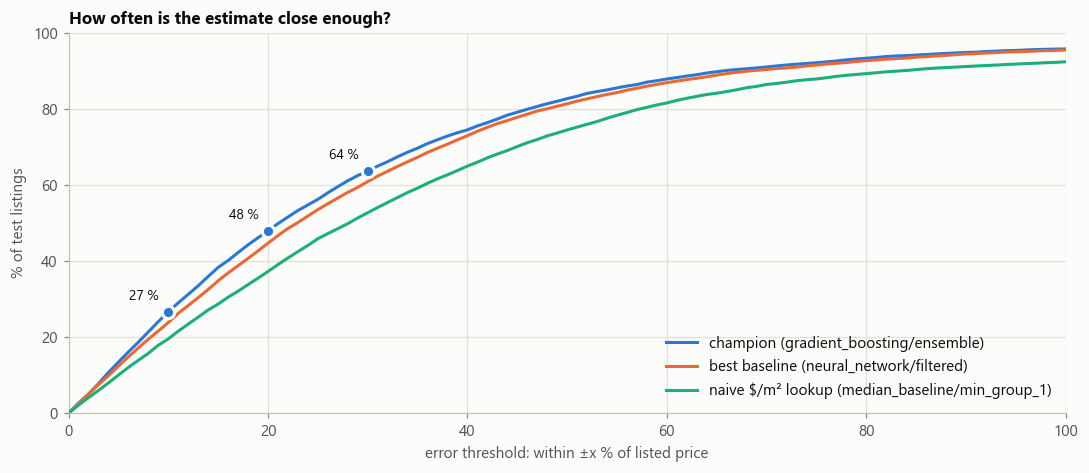

In [14]:
th = np.arange(0, 101)
fig, ax = plt.subplots(figsize=(10, 4.4))
for k, run in enumerate(CARD):
    q = preds[run]
    share = np.array([(q.ape <= t).mean() * 100 for t in th])
    ax.plot(th, share, color=SERIES[k], label=f"{ROLE[run]} ({run})", zorder=3)
    if run == FOCUS:
        for t in (10, 20, 30):
            ax.scatter(t, share[t], s=64, color=SERIES[k], edgecolor=SURFACE, linewidth=2, zorder=4)
            ax.annotate(f"{share[t]:.0f} %", (t, share[t]), xytext=(-6, 8), textcoords="offset points",
                        ha="right", fontsize=9, color=INK)
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="error threshold: within ±x % of listed price",
       ylabel="% of test listings")
ax.set_title("How often is the estimate close enough?")
ax.legend(loc="lower right")
fig.tight_layout()

## Noise floor: how much do identical listings disagree?
Before dedupe, `data.csv` had many listings with **identical features but different prices** (same project,
re-posts, different agents). For each one, the "best possible guess" is the median price of its identical twins.
The error of that guess is the noise floor: a model only sees the features, so it cannot do better on such rows.
Same row filters as `filter_data.ipynb` (no Land, no prices under $15k, no $/m² outliers), but before dedupe.
Caveat: only listings that have twins are measured, and those are mostly condos in big projects.

2,680 listings with identical twins in 897 groups; types: Condo 1984, Villa 216, Flat 167, Shophouse 156, Twin Villa 82, House 49, Link House 26
noise floor: MdAPE 13.5 %, within ±20 % 62 %


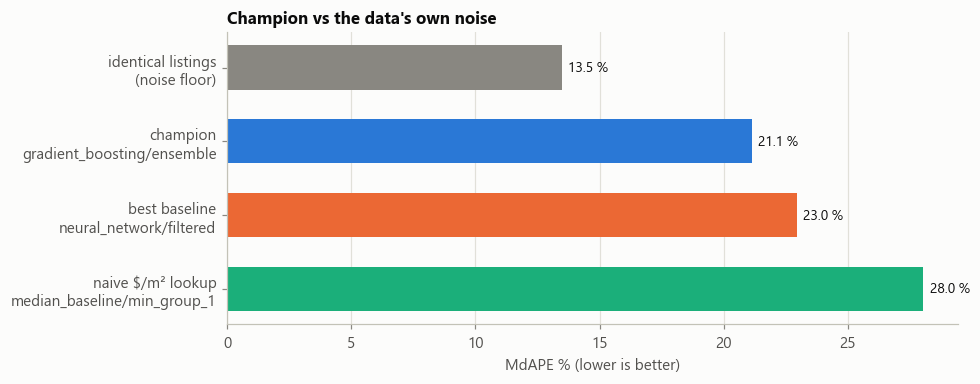

In [15]:
import yaml

cfg_nn = yaml.safe_load(open(LAB / "configs" / "neural_network_config.yml", encoding="utf-8"))
TARGET = cfg_nn["data"]["target"]
raw = pd.read_csv(LAB / "data" / "clean" / "data.csv", encoding="utf-8-sig", low_memory=False)
FEATS = [c for c in raw.columns if c != TARGET]

# filter_data.ipynb steps 1-3 (MIN_PRICE = 15k, Z_MAX = 3.5, drop Land)
log_ppm2 = np.log(raw[TARGET] / raw["area_m2"])
med = log_ppm2.groupby(raw["property_type"]).transform("median")
mad = (log_ppm2 - med).abs().groupby(raw["property_type"]).transform("median")
z = (log_ppm2 - med) / (1.4826 * mad)
raw = raw[(raw["property_type"] != "Land") & (raw[TARGET] >= 15_000) & (z.abs() <= 3.5)]

def leave_one_out_median(s):
    v = s.to_numpy()
    return pd.Series([np.median(np.delete(v, i)) for i in range(len(v))], index=s.index)

grp = raw.groupby(FEATS, dropna=False, sort=False)[TARGET]
twins = raw[grp.transform("size") > 1].copy()
twins["guess"] = twins.groupby(FEATS, dropna=False, sort=False)[TARGET].transform(leave_one_out_median)
twins["ape"] = (twins.guess - twins[TARGET]).abs() / twins[TARGET] * 100
FLOOR = twins.ape.median()
print(f"{len(twins):,} listings with identical twins in {twins.groupby(FEATS, dropna=False).ngroups:,} groups; "
      f"types: " + ", ".join(f"{t} {n}" for t, n in twins.property_type.value_counts().items()))
print(f"noise floor: MdAPE {FLOOR:.1f} %, within ±20 % {(twins.ape <= 20).mean() * 100:.0f} %")

bars = {"identical listings\n(noise floor)": FLOOR} | {f"{ROLE[r]}\n{r}": per_seed[r]["MdAPE %"].mean() for r in CARD}
fig, ax = plt.subplots(figsize=(9, 0.6 * len(bars) + 1.2))
colors = [MUTED] + SERIES[:len(CARD)]
ax.barh(list(bars), list(bars.values()), color=colors, height=0.6)
for i, v in enumerate(bars.values()):
    ax.annotate(f"{v:.1f} %", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(xlabel="MdAPE % (lower is better)")
ax.set_title("Champion vs the data's own noise")
fig.tight_layout()

## Where is it usable? (champion, by segment)
Accuracy within each property type and each price quarter (quarters of the listed price). `bias` = median
predicted / actual (×1.00 = unbiased). Segments with fewer than `MIN_ROWS` test rows per seed are left out.

In [16]:
q = p.copy()
n_s = q.seed.nunique()
_, edges = pd.qcut(q.actual, 4, retbins=True)
k_ = lambda v: f"${v / 1e6:.1f}M" if v >= 1e6 else f"${v / 1e3:.0f}k"
q["price quarter"] = pd.cut(q.actual, edges, include_lowest=True,
                            labels=[f"{k_(a)} – {k_(b)}" for a, b in zip(edges[:-1], edges[1:])])

def seg(g):
    return pd.Series({"rows/seed": len(g) / n_s, "MdAPE %": g.ape.median(),
                      "within ±20 %": (g.ape <= 20).mean() * 100,
                      "off by ×1.5+ %": ((g.predicted / g.actual >= 1.5) | (g.predicted / g.actual <= 1 / 1.5)).mean() * 100,
                      "bias": np.exp(g.log_err.median())})

segments = pd.concat({by: q.groupby(by, observed=True).apply(seg, include_groups=False) for by in ["property_type", "price quarter"]})
segments = segments[segments["rows/seed"] >= MIN_ROWS]
segments.index.names = ["segment", ""]
display(segments.style
        .format({"rows/seed": "{:.0f}", "MdAPE %": "{:.1f}", "within ±20 %": "{:.0f}",
                 "off by ×1.5+ %": "{:.0f}", "bias": "×{:.2f}"})
        .background_gradient(cmap=LinearSegmentedColormap.from_list("blues", BLUES), subset=["MdAPE %"]))

## How wide is an honest price range?
A single number hides the uncertainty. Here: the range that held the actual price for 80 % of test listings,
as a ratio of the estimate (from pooled test rows of all seeds). The app can show this as "estimated $X, likely
between $A and $B". Example column uses a $200k estimate.

In [17]:
LEVEL = 0.80
lo_q, hi_q = (1 - LEVEL) / 2, 1 - (1 - LEVEL) / 2
q["ratio"] = q.actual / q.predicted

def band(g):
    lo, hi = g.ratio.quantile([lo_q, hi_q])
    return pd.Series({"rows/seed": len(g) / n_s, "low ×": lo, "high ×": hi,
                      "$200k estimate →": f"{k_(200_000 * lo)} – {k_(200_000 * hi)}"})

types_ok = (q.property_type.value_counts() / n_s).loc[lambda s: s >= MIN_ROWS].index
bands = pd.concat([band(q).to_frame("all").T,
                   q[q.property_type.isin(types_ok)].groupby("property_type").apply(band, include_groups=False)])
display(bands.style.format({"rows/seed": "{:.0f}", "low ×": "×{:.2f}", "high ×": "×{:.2f}"}))
INTERVAL = bands.loc["all", ["low ×", "high ×"]].astype(float)
print(f"{LEVEL:.0%} of actual prices lie between ×{INTERVAL['low ×']:.2f} and ×{INTERVAL['high ×']:.2f} of the estimate. "
      "Measured on test rows; for the app, compute it on validation rows so it is not tuned on the test set.")

,rows/seed,low ×,high ×,$200k estimate →
all,2060,×0.63,×1.61,$126k – $322k
Condo,773,×0.67,×1.50,$134k – $299k
Flat,276,×0.60,×1.81,$120k – $362k
House,247,×0.50,×2.18,$101k – $436k
Link House,63,×0.63,×1.38,$127k – $276k
Shophouse,211,×0.58,×1.72,$117k – $345k
Twin Villa,80,×0.80,×1.28,$160k – $257k
Villa,410,×0.66,×1.54,$132k – $307k


80% of actual prices lie between ×0.63 and ×1.61 of the estimate. Measured on test rows; for the app, compute it on validation rows so it is not tuned on the test set.


## Verdict
Pulls the numbers above together. Text is generated, so it updates when the runs change.

In [18]:
c, b, nv = (per_seed[r].mean() if r else None for r in (FOCUS, BEST_BASE, NAIVE))
worst = segments.sort_values("MdAPE %", ascending=False).head(3)
best_seg = segments.sort_values("MdAPE %").head(3)
out = [f"Champion: {FOCUS}",
       f"- Typical error (MdAPE) {c['MdAPE %']:.1f} %: half of estimates are within ±{c['MdAPE %']:.0f} % of the listed price "
       f"(median miss ${c['median abs error $']:,.0f} on a median price of ${c['median price $']:,.0f}).",
       f"- {c['within ±20 %']:.0f} % within ±20 %, {c['within ±10 %']:.0f} % within ±10 %; "
       f"{c['off by ×1.5+ %']:.0f} % off by ×1.5 or more."]
if nv is not None:
    out.append(f"- vs naive $/m² lookup ({NAIVE}): MdAPE {nv['MdAPE %']:.1f} % → {c['MdAPE %']:.1f} % "
               f"({(1 - c['MdAPE %'] / nv['MdAPE %']) * 100:.0f} % lower); within ±20 % {nv['within ±20 %']:.0f} % → {c['within ±20 %']:.0f} %.")
if b is not None and BEST_BASE != NAIVE:
    out.append(f"- vs best baseline ({BEST_BASE}): MdAPE {b['MdAPE %']:.1f} % → {c['MdAPE %']:.1f} %.")
out.append(f"- Noise floor (identical listings): MdAPE {FLOOR:.1f} %. Champion is {c['MdAPE %'] / FLOOR:.1f}× the floor"
           + (" → close to what the data allows; more accuracy needs better data, not a better model."
              if c["MdAPE %"] <= 1.5 * FLOOR else " → room left for better features / models."))
out.append(f"- Targets met: {sum(met.values())} of {len(met)} ("
           + ", ".join(f"{k} {TARGETS[k][0]} {TARGETS[k][1]} {'✓' if v else '✗'}" for k, v in met.items()) + ").")
out.append(f"- {LEVEL:.0%} price range: ×{INTERVAL['low ×']:.2f} – ×{INTERVAL['high ×']:.2f} of the estimate.")
out.append("- Most reliable: " + ", ".join(f"{i[1]} ({r['MdAPE %']:.0f} %)" for i, r in best_seg.iterrows()))
out.append("- Least reliable: " + ", ".join(f"{i[1]} ({r['MdAPE %']:.0f} %)" for i, r in worst.iterrows()))
print("\n".join(out))

Champion: gradient_boosting/ensemble
- Typical error (MdAPE) 21.1 %: half of estimates are within ±21 % of the listed price (median miss $34,106 on a median price of $167,886).
- 48 % within ±20 %, 27 % within ±10 %; 25 % off by ×1.5 or more.
- vs naive $/m² lookup (median_baseline/min_group_1): MdAPE 28.0 % → 21.1 % (25 % lower); within ±20 % 37 % → 48 %.
- vs best baseline (neural_network/filtered): MdAPE 23.0 % → 21.1 %.
- Noise floor (identical listings): MdAPE 13.5 %. Champion is 1.6× the floor → room left for better features / models.
- Targets met: 0 of 3 (MdAPE % <= 20 ✗, within ±20 % >= 50 ✗, off by ×1.5+ % <= 10 ✗).
- 80% price range: ×0.63 – ×1.61 of the estimate.
- Most reliable: Twin Villa (12 %), Link House (17 %), $169k – $345k (18 %)
- Least reliable: House (34 %), Flat (26 %), Shophouse (26 %)
